In [1]:
import os
import subprocess
from pathlib import Path
import tempfile

try:
    _printenv = subprocess.run(
        ['bash', '-c', 'source ~/.bashrc 2>/dev/null && printenv'],
        text=True, capture_output=True, timeout=10,
    ).stdout
    for _line in _printenv.splitlines():
        if '=' in _line:
            _k, _v = _line.split('=', 1)
            os.environ.setdefault(_k, _v)
except Exception:
    pass
if 'PDK_ROOT' in os.environ and 'PDK' in os.environ:
    os.environ.setdefault('PDKPATH', os.path.join(os.environ['PDK_ROOT'], os.environ['PDK']))

import gdstk
import svgutils.transform as sg
import IPython.display
from IPython.display import clear_output
import ipywidgets as widgets

# Redirect all outputs here
hide = widgets.Output()

def display_gds(gds_file,path,scale = 3):
  
  # Generate an SVG image
  top_level_cell = gdstk.read_gds(gds_file).top_level()[0]
  top_level_cell.write_svg(os.path.join(path,'out.svg'))
    
  # Scale the image for displaying
  fig = sg.fromfile(os.path.join(path,'out.svg'))
  fig.set_size((str(float(fig.width) * scale), str(float(fig.height) * scale)))
  fig.save(os.path.join(path,'out.svg'))

  # Display the image
  IPython.display.display(IPython.display.SVG(os.path.join(path,'out.svg')))
  os.remove(os.path.join(path,'out.gds'))

def display_component(component,path,scale = 3):
  # Save to a GDS file
  with hide:
    component.write_gds(os.path.join(path,'out.gds'))
  display_gds(os.path.join(path,'out.gds'),path,scale)

import gdsfactory as gf
from gdsfactory import Component
from gdsfactory.components import text_freetype, rectangle
from glayout import MappedPDK, sky130, gf180
from glayout import nmos, pmos
from glayout import via_stack
from glayout import rename_ports_by_orientation
from glayout import tapring
from glayout.primitives.mimcap import mimcap_array, mimcap
from glayout.routing.straight_route import straight_route
from glayout.routing.c_route import c_route
from glayout.routing.L_route import L_route
from glayout.util.comp_utils import evaluate_bbox, prec_center, prec_ref_center, align_comp_to_port
from glayout.util.port_utils import add_ports_perimeter,print_ports
from glayout.util.snap_to_grid import component_snap_to_grid
from glayout.spice.netlist import Netlist

pdk = sky130
# Base parameters for PMOS and NMOS
stdp_config = {
    "pdk": pdk,
    "layout_rules": {
        "spacing": pdk.util_max_metal_seperation()+1.5,
        "routing_metal": "met2",
        "dummy_devices": False,
        "tie_layers": ("met2", "met1"),
        "sd_rmult": 1,
    },
}

nmos_kwargs = {
    "with_tie": True,
    "with_dnwell": False,
    "sd_route_topmet": "met2",
    "gate_route_topmet": "met2",
    "sd_route_left": True,
    "rmult": None,
    "gate_rmult": 1,
    "with_dummy": (False, False),
    "interfinger_rmult": 1,
    "substrate_tap_layers": ("met2","met1"),
    "dummy_routes": False,
    "with_substrate_tap": False
}

pmos_kwargs = {
    "with_tie": True,
    "dnwell": False,
    "sd_route_topmet": "met2",
    "gate_route_topmet": "met2",
    "sd_route_left": True,
    "rmult": None,
    "gate_rmult": 1,
    "with_dummy": (False, False),
    "interfinger_rmult": 1,
    "substrate_tap_layers": ("met2","met1"),
    "dummy_routes": False,
    "with_substrate_tap": False
}

stdp_comp = Component(name="stdp")
stdp_comp.name = "stdp"
rules = stdp_config["layout_rules"]
spacing = rules["spacing"]
tie_layers = rules["tie_layers"]
sd_rmult = rules["sd_rmult"]

In [2]:
# =========================================================================
# 1. INSTANTIATE ALL DEVICES MATCHING SPICE NETLIST
# =========================================================================

# --- PMOS TRANSISTORS --- 
m3 = pmos(pdk, width=1, length=0.15, tie_layers=tie_layers, sd_rmult=sd_rmult, **pmos_kwargs)
m4 = pmos(pdk, width=1, length=0.15, tie_layers=tie_layers, sd_rmult=sd_rmult, **pmos_kwargs)
m5 = pmos(pdk, width=1, length=0.15, tie_layers=tie_layers, sd_rmult=sd_rmult, **pmos_kwargs)
m6 = pmos(pdk, width=0.5, length=0.15, tie_layers=tie_layers, sd_rmult=sd_rmult, **pmos_kwargs)
m7 = pmos(pdk, width=0.5, length=0.15, tie_layers=tie_layers, sd_rmult=sd_rmult, **pmos_kwargs)

# --- NMOS TRANSISTORS --- 
m1 = nmos(pdk, width=0.5, length=0.15, tie_layers=tie_layers, sd_rmult=sd_rmult, **nmos_kwargs)
m2 = nmos(pdk, width=0.5, length=0.15, tie_layers=tie_layers, sd_rmult=sd_rmult, **nmos_kwargs)



m1.name = "m1"
m2.name = "m2"
m3.name = "m3"
m4.name = "m4"
m5.name = "m5"
m6.name = "m6"
m7.name = "m7"


# Add components to subcircuit
m1_ref = stdp_comp << m1
m2_ref = stdp_comp << m2
m3_ref = stdp_comp << m3
m4_ref = stdp_comp << m4
m5_ref = stdp_comp << m5
m6_ref = stdp_comp << m6
m7_ref = stdp_comp << m7


# =========================================================================
# 2. PLACEMENT & FLOORPLANNING
# =========================================================================


bottom_row = evaluate_bbox(m5_ref)[1]/2
# → Altura de la fila inferior (NMOS), usando la mitad de la dimensión Y de M2

middle_row = bottom_row + evaluate_bbox(m5_ref)[1]
# → Fila intermedia: se coloca justo encima de la fila inferior,
#   sumando la altura del transistor de reset (M5)

top_row = middle_row + evaluate_bbox(m1_ref)[1] + 2
# → Fila superior: encima de la fila intermedia,
#   sumando la altura de un PMOS (M1) y un margen extra de 2 unidades
spacing_x = 1.5
spacing_y = 1.5
#-------------------------------------------------------------------------------

# --- Colocación de PMOS en la fila superior ---
m3_ref.move((0 + evaluate_bbox(m3_ref)[0]/2, bottom_row + evaluate_bbox(m3_ref)[1] + spacing_y))
# → M1 se coloca en el origen X, centrado en su ancho, y en la fila superior

m4_ref.move((m3_ref.xmax + evaluate_bbox(m4_ref)[0]/2 + spacing_x, bottom_row + evaluate_bbox(m4_ref)[1] + spacing_y))
# → M3 se coloca a la derecha de M1, usando xmax de M1 como referencia

m5_ref.move((m4_ref.xmax + evaluate_bbox(m5_ref)[0]/2 + spacing_x, bottom_row + evaluate_bbox(m5_ref)[1] + spacing_y))
# → M6 se coloca a la derecha de M3

m6_ref.move((m5_ref.xmax + evaluate_bbox(m6_ref)[0]/2 + spacing_x, bottom_row + evaluate_bbox(m6_ref)[1] + spacing_y + 0.25))
# → M6 se coloca a la derecha de M3

# --- Colocación de NMOS en la fila inferior ---
m1_ref.move((0 + evaluate_bbox(m1_ref)[0]/2, bottom_row))
# → M2 en el origen X, centrado, en la fila inferior

m2_ref.move((m1_ref.xmax + evaluate_bbox(m1_ref)[0]/2 + spacing_x, bottom_row))
# → M4 a la derecha de M2

m7_ref.move((m5_ref.xmax + evaluate_bbox(m1_ref)[0]/2 + spacing_x, bottom_row))
# → M4 a la derecha de M2



2026-10-31 02:10:49.543 | INFO     | gdsfactory.pdk:activate:337 - 'sky130' PDK is now active


ComponentReference (parent Component "m7", ports ['multiplier_0_gate_W', 'gate_W', 'multiplier_0_row0_col0_gate_W', 'multiplier_0_row0_col0_rightsd_array_row0_col0_bottom_layer_W', 'multiplier_0_row0_col0_rightsd_array_row0_col0_bottom_via_W', 'multiplier_0_row0_col0_rightsd_array_row0_col0_bottom_met_W', 'multiplier_0_row0_col0_rightsd_array_row0_col0_top_met_W', 'multiplier_0_row0_col0_rightsd_top_met_W', 'multiplier_0_leftsd_array_row0_col0_bottom_layer_W', 'multiplier_0_leftsd_array_row0_col0_bottom_via_W', 'multiplier_0_leftsd_array_row0_col0_bottom_met_W', 'multiplier_0_leftsd_array_row0_col0_top_met_W', 'multiplier_0_leftsd_top_met_W', 'multiplier_0_plusdoped_W', 'multiplier_0_diff_W', 'multiplier_0_source_W', 'source_W', 'multiplier_0_drain_W', 'drain_W', 'multiplier_0_leftsd_array_row0_col0_bottom_layer_N', 'multiplier_0_leftsd_array_row0_col0_bottom_via_N', 'multiplier_0_leftsd_array_row0_col0_bottom_met_N', 'multiplier_0_leftsd_array_row0_col0_top_met_N', 'multiplier_0_lefts

2026-10-31 02:10:56.516 | INFO     | gdsfactory.klive:show:55 - Message from klive: {"version": "0.4.1", "klayout_version": "0.30.8", "type": "reload", "file": "/tmp/gdsfactory/stdp.gds"}


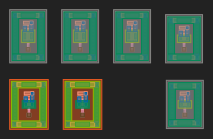

In [3]:
stdp_comp.show()
display_component(stdp_comp, scale = 1,path=".")

In [4]:
memristor = gf.read.import_gds(gdspath= "/foss/designs/libs/snn_analog/rram.gds")
mem_ref = stdp_comp << memristor
mem_ref.name = "memristor"
mem_ref.move(m1_ref.ports["drain_E"].center).movex(2.5)

ComponentReference (parent Component "(UNNAMED)", ports [], origin (4.9, 3.785), rotation 0.0, x_reflection False)

2026-10-31 02:10:56.669 | INFO     | gdsfactory.klive:show:55 - Message from klive: {"version": "0.4.1", "klayout_version": "0.30.8", "type": "reload", "file": "/tmp/gdsfactory/stdp.gds"}


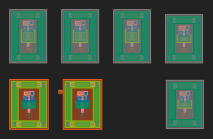

In [5]:
stdp_comp.show()
display_component(stdp_comp, scale = 1,path=".")

In [6]:
# =========================================================================
# 4. ADD AVDD & AVSS POWER RAILS AND CONNECT SUPPLY NODES
# =========================================================================

bbox = evaluate_bbox(stdp_comp)
top_y = stdp_comp.ymax + 1.0
bottom_y = stdp_comp.ymin - 2.0

# Draw horizontal metal2 power rails
avdd_rail = stdp_comp << gf.components.rectangle(
    size=(bbox[0]+4, 1.0), 
    layer=pdk.get_layer("met3")
)
avdd_rail.move((-2, top_y))

avss_rail = stdp_comp << gf.components.rectangle(
    size=(bbox[0]+4, 1.0), 
    layer=pdk.get_layer("met3")
)
avss_rail.move((-2, bottom_y))


#adding a VIA M2M3 to the avdd avss pin, moving to the center of the rail
viam2m3 = via_stack(pdk, "met2", "met4", centered=True) #met2 is the bottom layer. met5 is the top layer.
via_avdd = stdp_comp << viam2m3
via_avdd.move((bbox[0]/2, top_y + 0.5))
via_avss = stdp_comp << viam2m3
via_avss.move((bbox[0]/2, bottom_y + 0.5))

ComponentReference (parent Component "via_stack_0d486145", ports ['bottom_layer_W', 'bottom_layer_N', 'bottom_layer_E', 'bottom_layer_S', 'bottom_via_W', 'bottom_via_N', 'bottom_via_E', 'bottom_via_S', 'bottom_met_W', 'bottom_met_N', 'bottom_met_E', 'bottom_met_S', 'top_met_W', 'top_met_N', 'top_met_E', 'top_met_S'], origin (9.69, -1.33), rotation 0.0, x_reflection False)

2026-10-31 02:10:56.850 | INFO     | gdsfactory.klive:show:55 - Message from klive: {"version": "0.4.1", "klayout_version": "0.30.8", "type": "reload", "file": "/tmp/gdsfactory/stdp.gds"}


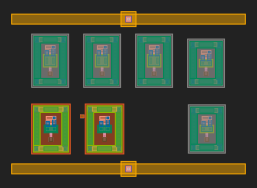

In [7]:
stdp_comp.show()
display_component(stdp_comp, scale = 1,path=".")

In [8]:
# =========================================================================
# 3. ROUTING & NET CONNECTIONS
# =========================================================================

stdp_comp << L_route(pdk, m3_ref.ports["tie_N_top_met_N"], via_avdd.ports["bottom_met_W"])
stdp_comp << L_route(pdk, m4_ref.ports["tie_N_top_met_N"], via_avdd.ports["bottom_met_W"])
stdp_comp << L_route(pdk, m5_ref.ports["tie_N_top_met_N"], via_avdd.ports["bottom_met_W"])
stdp_comp << L_route(pdk, m6_ref.ports["tie_N_top_met_N"], via_avdd.ports["bottom_met_W"])
stdp_comp << straight_route(pdk, m7_ref.ports["tie_N_top_met_N"], m6_ref.ports["tie_S_top_met_S"])

# Connect NMOS BULKS TO AVSS
stdp_comp << L_route(pdk, m1_ref.ports["tie_S_top_met_S"], via_avss.ports["bottom_met_W"])
stdp_comp << L_route(pdk, m2_ref.ports["tie_S_top_met_S"], via_avss.ports["bottom_met_W"])

stdp_comp << straight_route(pdk, m1_ref.ports["source_W"], m1_ref.ports["tie_W_top_met_E"])
stdp_comp << straight_route(pdk, m2_ref.ports["source_W"], m2_ref.ports["tie_W_top_met_E"])
stdp_comp << straight_route(pdk, m3_ref.ports["source_W"], m3_ref.ports["tie_W_top_met_E"])
stdp_comp << straight_route(pdk, m4_ref.ports["source_W"], m4_ref.ports["tie_W_top_met_E"])
stdp_comp << straight_route(pdk, m5_ref.ports["source_W"], m5_ref.ports["tie_W_top_met_E"])
stdp_comp << straight_route(pdk, m6_ref.ports["source_W"], m6_ref.ports["tie_W_top_met_E"])
stdp_comp << straight_route(pdk, m7_ref.ports["source_W"], m7_ref.ports["tie_W_top_met_E"])


ComponentReference (parent Component "straight_route_b5dc7cca", ports ['route_W', 'route_N', 'route_E', 'route_S'], origin (0.0, 0.0), rotation 0.0, x_reflection False)

2026-10-31 02:10:57.755 | INFO     | gdsfactory.klive:show:55 - Message from klive: {"version": "0.4.1", "klayout_version": "0.30.8", "type": "reload", "file": "/tmp/gdsfactory/stdp.gds"}


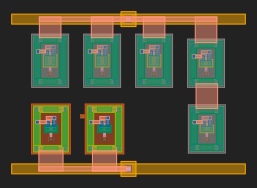

In [9]:
stdp_comp.show()
display_component(stdp_comp, scale = 1,path=".")

In [10]:
viam2m4 = via_stack(pdk, "met2", "met3", centered=True)
vpost_via = stdp_comp << viam2m4
vpre_via = stdp_comp << viam2m4
nvpost_via = stdp_comp << viam2m4
nvpre_via = stdp_comp << viam2m4
ipost_via = stdp_comp << viam2m4

viam2m3 = via_stack(pdk, "met2", "met3", centered=True)
m5gate_via = stdp_comp << viam2m3
m4gate_via = stdp_comp << viam2m3
m2gate_via = stdp_comp << viam2m3



vpost_via.move(m1_ref.ports["multiplier_0_gate_W"].center).movex(-3)
vpre_via.move(m2_ref.ports["multiplier_0_gate_E"].center).movex(13.4)
nvpre_via.move(m3_ref.ports["multiplier_0_gate_W"].center).movex(-3)
nvpost_via.move(m4_ref.ports["multiplier_0_gate_E"].center).movex(-8.5).movey(-2)
ipost_via.move(m7_ref.ports["multiplier_0_drain_E"].center).movex(3)

m5gate_via.move(m5_ref.ports["gate_W"].center).movex(-1.8)
m4gate_via.move(m4_ref.ports["gate_E"].center).movey(-2).movex(-2.5)
m2gate_via.move(m2_ref.ports["gate_E"].center).movex(5)




# CONEXIONES
# current mirror
stdp_comp << straight_route(pdk, m1_ref.ports["gate_W"], vpost_via.ports["bottom_met_E"])
stdp_comp << straight_route(pdk, m3_ref.ports["gate_W"], nvpre_via.ports["bottom_met_E"])
stdp_comp << straight_route(pdk, m7_ref.ports["drain_E"], ipost_via.ports["bottom_met_E"])
stdp_comp << L_route(pdk, m4_ref.ports["source_E"], m5gate_via.ports["bottom_met_N"])
stdp_comp << straight_route(pdk, m5_ref.ports["gate_W"], m5gate_via.ports["bottom_met_E"])
stdp_comp << straight_route(pdk, m4gate_via.ports["bottom_met_E"], nvpost_via.ports["bottom_met_E"])
stdp_comp << L_route(pdk, m4gate_via.ports["bottom_met_N"], m4_ref.ports["gate_W"])
stdp_comp << straight_route(pdk, m2gate_via.ports["bottom_met_W"], m2_ref.ports["gate_E"])
stdp_comp << c_route(pdk, m2gate_via.ports["top_met_S"], vpre_via.ports["top_met_S"], e1glayer="met3", e2glayer="met3",cglayer="met2", extension=1.5)







stdp_comp << straight_route(pdk, m3_ref.ports["source_E"], m4_ref.ports["drain_W"])
stdp_comp << c_route(pdk, m3_ref.ports["drain_E"], m1_ref.ports["drain_E"], extension=1)
stdp_comp << c_route(pdk, m4_ref.ports["drain_E"], m2_ref.ports["drain_E"], extension=1)
stdp_comp << straight_route(pdk, m5_ref.ports["gate_E"], m6_ref.ports["gate_W"])
stdp_comp << c_route(pdk, m6_ref.ports["gate_W"], m7_ref.ports["gate_W"], extension=1)
stdp_comp << c_route(pdk, m5_ref.ports["drain_E"], m5_ref.ports["gate_E"], extension=1)


ComponentReference (parent Component "c_route_f3d50092", ports ['con_N', 'con_S'], origin (0.0, 0.0), rotation 0.0, x_reflection False)

2026-10-31 02:10:58.843 | INFO     | gdsfactory.klive:show:55 - Message from klive: {"version": "0.4.1", "klayout_version": "0.30.8", "type": "reload", "file": "/tmp/gdsfactory/stdp.gds"}


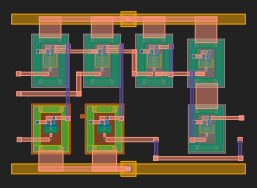

In [11]:
stdp_comp.show()
display_component(stdp_comp, scale = 1,path=".")

In [12]:
#----------- Adding snippet code to move all the placed components to the proper position, 
#----------- in order to set origin into 0,0
# Place this snippet after all your material polygones are placed, and before your ports are placed
bbox = stdp_comp.bbox[0]
for ref in stdp_comp.references:
    ref.movex(-1*bbox[0]).movey(-1*bbox[1])

2026-10-31 02:10:59.096 | INFO     | gdsfactory.klive:show:55 - Message from klive: {"version": "0.4.1", "klayout_version": "0.30.8", "type": "reload", "file": "/tmp/gdsfactory/stdp.gds"}


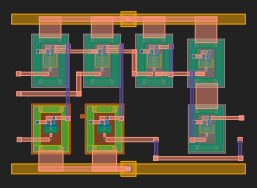

In [13]:
stdp_comp.show()
display_component(stdp_comp, scale = 1,path=".")

In [14]:
# =========================================================================
# 5. ADD MET2 PHYSICAL PINS AND LABELS FOR LVS
# =========================================================================

# Add global ports for the supply rails
stdp_comp.add_port("vdd", center=via_avdd.center, width=evaluate_bbox(via_avdd)[0], orientation=0, layer=pdk.get_layer("met3"), port_type="electrical")
stdp_comp.add_port("vss", center=via_avss.center, width=evaluate_bbox(via_avss)[0], orientation=0, layer=pdk.get_layer("met3"), port_type="electrical")
# add label to those global ports 
stdp_comp.add_label(text="vdd", position=via_avdd.center, layer=pdk.get_glayer("met4_label") , magnification=1.2)
stdp_comp.add_label(text="vss", position=via_avss.center, layer=pdk.get_glayer("met4_label") , magnification=1.2)


# Map port names to their source port objects
pins_to_create = {
    "nvpost": nvpost_via,
    "vpost": vpost_via,
    "vpre": vpre_via,
    "nvpre": nvpre_via,
}
pins_to_create = {
    "nvpost":     (nvpost_via, 180, "met2", "met3_label", 1.5),
    "vpost":     (vpost_via, 180, "met2", "met3_label", 1.5),
    "vpre":     (vpre_via, 180, "met2", "met3_label", 1.5),
    "nvpre": (nvpre_via, 180, "met2", "met3_label", 1.5),
    "i_post": (ipost_via, 270, "met2", "met3_label", 1.5)
}

for pin_name, (ref_obj, orient, p_layer, l_layer, mag) in pins_to_create.items():
    # Extract center position from the reference object
    center = ref_obj.center
    
    # 1. Add port
    stdp_comp.add_port(
        name=pin_name, 
        center=center, 
        width=1.0, 
        orientation=orient, 
        layer=pdk.get_layer(p_layer),  
        port_type="electrical"
    ) 

    # 2. Add text label on the corresponding label layer for net identity
    stdp_comp.add_label(
        text=pin_name, 
        position=center, 
        layer=pdk.get_glayer(l_layer), 
        magnification=mag
    )
    

2026-10-31 02:10:59.281 | INFO     | gdsfactory.klive:show:55 - Message from klive: {"version": "0.4.1", "klayout_version": "0.30.8", "type": "reload", "file": "/tmp/gdsfactory/stdp.gds"}


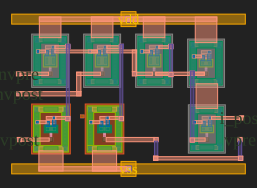

In [15]:
stdp_comp.show()
display_component(stdp_comp, scale = 1,path=".")

In [16]:
stdp_comp.pprint_ports()

┏━━━━━━━━┳━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━┓
┃ name   ┃ width ┃ center         ┃ orientation ┃ layer    ┃ port_type  ┃
┡━━━━━━━━╇━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━┩
│ vdd    │ 1.5   │ [11.69, 15.78] │ 0           │ [70, 20] │ electrical │
│ vss    │ 1.5   │ [11.69, 0.75]  │ 0           │ [70, 20] │ electrical │
│ nvpost │ 1.0   │ [0.715, 8.29]  │ 180         │ [69, 20] │ electrical │
│ vpost  │ 1.0   │ [0.765, 3.69]  │ 180         │ [69, 20] │ electrical │
│ vpre   │ 1.0   │ [22.855, 3.69] │ 180         │ [69, 20] │ electrical │
│ nvpre  │ 1.0   │ [0.685, 10.29] │ 180         │ [69, 20] │ electrical │
│ i_post │ 1.0   │ [23.0, 5.865]  │ 270         │ [69, 20] │ electrical │
└────────┴───────┴────────────────┴─────────────┴──────────┴────────────┘

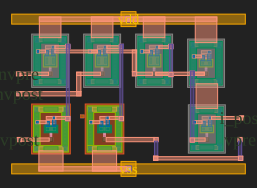

In [17]:
display_component(stdp_comp, scale = 1,path=".")

In [18]:
drc_result = pdk.drc_magic(stdp_comp, stdp_comp.name)

2026-10-31 02:11:02.189 | INFO     | gdsfactory.component:_write_library:1851 - Wrote to '/tmp/tmp84dlyb06/stdp.gds'


using default pdk_root
Defaulting to stale magic_commands.tcl

Magic 8.3 revision 636 - Compiled on Thu Apr 16 09:13:57 PM CEST 2026.
Starting magic under Tcl interpreter
Using the terminal as the console.
Using NULL graphics device.
Processing system .magicrc file
Switching to WIRING tool.
Switching to NETLIST tool.
Switching to PICK tool.
Switching to BOX tool.
Sourcing design .magicrc for technology sky130A ...
2 Magic internal units = 1 Lambda
Input style sky130(): scaleFactor=2, multiplier=2
The following types are not handled by extraction and will be treated as non-electrical types:
    ubm 
Scaled tech values by 2 / 1 to match internal grid scaling
Loading sky130A Device Generator Menu ...
Loading "/tmp/tmp84dlyb06/magic_commands.tcl" from command line.
Library written using GDS-II Release 6.0
Library name: library
Reading "stdp".
Reading "straight_route_bbbe5c68".
Reading "m4".
Reading "c_route_7c9c68e3".
Reading "straight_route_723c1384".
Reading "straight_route_ac5230a7".
Re

In [23]:

import os
from pathlib import Path
import tempfile
magicrc_file = Path(os.environ['PDKPATH']) / "libs.tech" / "magic" / f"{os.environ['PDK']}.magicrc"
design_name=stdp_comp.name
path_to_dir = "/foss/designs/libs/snn_analog/stdp/"

pex_path = path_to_dir + "spice/" + f"{design_name}.spice"
gds_path = path_to_dir + "gds/" + f"{design_name}.gds"
lef_path = path_to_dir + "lef/" + f"{design_name}.lef"

stdp_comp.write_gds(str(gds_path))

magic_script_content = f"""
drc off            
gds flatglob *\\$\\$*
gds read {gds_path}

flatten {design_name}
load {design_name}
select top cell
extract do local
extract all
ext2sim labels on
ext2sim
extresist tolerance 10
extresist
ext2spice lvs
ext2spice cthresh 0
ext2spice extresist on
ext2spice -o {str(pex_path)}
port avdd use power
port avss use ground
lef write {lef_path}
exit
"""


with tempfile.NamedTemporaryFile(mode='w', delete=False) as magic_script_file:
    magic_script_file.write(magic_script_content)
    magic_script_path = magic_script_file.name
    
magic_cmd = f"bash -c 'magic -rcfile {magicrc_file} -noconsole -dnull < {magic_script_path}'",
magic_subproc = subprocess.run(
    magic_cmd, 
    shell=True,
    check=True,
    capture_output=True
)

magic_subproc_code = magic_subproc.returncode
magic_subproc_out = magic_subproc.stdout.decode('utf-8')
print(magic_subproc_out)



2026-09-07 19:28:57.231 | INFO     | gdsfactory.component:_write_library:1851 - Wrote to '/foss/designs/libs/snn_analog/stdp/stdp.gds'



Magic 8.3 revision 636 - Compiled on Thu Apr 16 09:17:18 PM CEST 2026.
Starting magic under Tcl interpreter
Using the terminal as the console.
Using NULL graphics device.
Processing system .magicrc file
Switching to WIRING tool.
Switching to NETLIST tool.
Switching to PICK tool.
Switching to BOX tool.
Sourcing design .magicrc for technology gf180mcuD ...
10 Magic internal units = 1 Lambda
Input style import: scaleFactor=10, multiplier=2
The following types are not handled by extraction and will be treated as non-electrical types:
    obsactive mvobsactive filldiff fillpoly m1hole obsm1 fillm1 obsv1 m2hole obsm2 fillm2 obsv2 m3hole obsm3 fillm3 m4hole obsm4 fillm4 m5hole obsm5 fillm5 glass fillblock lvstext obscomment 
Scaled tech values by 10 / 1 to match internal grid scaling
Loading gf180mcuD Device Generator Menu ...
Using technology "gf180mcuD", version 1.0.575-2-g7b70722
Library written using GDS-II Release 6.0
Library name: library
Reading "stdp".
Reading "L_route_47683042".
Rea

In [24]:
import glob
extensions = [
            "els"
            "*.gds",
            "*.ext",
            "*.res.ext",
            "*.lvs.rpt",
            "*_lvs.rpt",
            "*.nodes",
            "*.sim",
            "*.pex.spice",
            "*_pex.spice"
            ]
files_to_delete = []
for ext in extensions:
    files_to_delete.extend(glob.glob(ext))
    
# Delete the files
for file_path in files_to_delete:
    try:
        os.remove(file_path)
        print(f"Deleted: {file_path}")
    except OSError as e:
        print(f"Error deleting {file_path}: {e}")

Deleted: rectangle_layer42__0_size2__2$3.ext
Deleted: L_route_9c9fed4d.ext
Deleted: compass_layer42__0_size2__2$3.ext
Deleted: straight_route_d6a45d2e.ext
Deleted: L_route_7418b0f0.ext
Deleted: compass_layer42__0_size2__2$2.ext
Deleted: L_route_a4b8e0be.ext
Deleted: straight_route_d412d36f.ext
Deleted: rectangle_layer42__0_size2__2$2.ext
Deleted: L_route_97c034e0.ext
Deleted: rectangle_layer42__0_size2__2.ext
Deleted: L_route_7977193d.ext
Deleted: c_route_79ac5c6e.ext
Deleted: rectangle_94007988.ext
Deleted: compass_layer42__0_size2__2$1.ext
Deleted: L_route_f3c37f7c.ext
Deleted: straight_route_4f7b53c4.ext
Deleted: via_stack_7fdd5994.ext
Deleted: rectangle_layer42__0_size2__2$1.ext
Deleted: rectangle_layer42__0_size2__2$5.ext
Deleted: L_route_15a0f388.ext
Deleted: compass_layer42__0_size2__2$5.ext
Deleted: compass_layer42__0_size2__2$4.ext
Deleted: c_route_5d5d9dce.ext
Deleted: rectangle_layer42__0_size2__2$4.ext
Deleted: rectangle_layer42__0_size2__2$6.ext
Deleted: L_route_c02104a2.e

In [25]:

gf180.lvs_netgen(
    layout= Path(str(path_to_dir + "stdp.gds")),
    design_name = stdp_comp.name,
    pdk_root = Path(os.environ['PDKPATH']),
    lvs_setup_tcl_file = Path(os.environ['PDKPATH']) / "libs.tech" / "netgen" / f"{os.environ['PDK']}_setup.tcl",
    lvs_schematic_ref_file = Path(str(path_to_dir + "stdp.spice")),
    netlist = Path(str(path_to_dir + "stdp_sch.spice")),
    output_file_path =  Path(str(path_to_dir))
)




using user specified pdk_root, will search for required files in the specified directory

Magic 8.3 revision 636 - Compiled on Thu Apr 16 09:17:18 PM CEST 2026.
Starting magic under Tcl interpreter
Using the terminal as the console.
Using NULL graphics device.
Processing system .magicrc file
Switching to WIRING tool.
Switching to NETLIST tool.
Switching to PICK tool.
Switching to BOX tool.
Sourcing design .magicrc for technology gf180mcuD ...
10 Magic internal units = 1 Lambda
Input style import: scaleFactor=10, multiplier=2
The following types are not handled by extraction and will be treated as non-electrical types:
    obsactive mvobsactive filldiff fillpoly m1hole obsm1 fillm1 obsv1 m2hole obsm2 fillm2 obsv2 m3hole obsm3 fillm3 m4hole obsm4 fillm4 m5hole obsm5 fillm5 glass fillblock lvstext obscomment 
Scaled tech values by 10 / 1 to match internal grid scaling
Loading gf180mcuD Device Generator Menu ...
Using technology "gf180mcuD", version 1.0.575-2-g7b70722
Library written using

{'magic_subproc_code': 0,
 'netgen_subproc_code': 0,
 'result_str': 'LVS run succeeded\nErrors found in LVS report: /tmp/tmpix2pnmir/stdp_lvs.rpt'}